## Delhi Air Quality Cleaning: PM2.5 and NO2 (March-November 2025)

**Prepared by:** Yashvi Patel

This notebook prepares and checks the hourly Delhi PM2.5 and NO2 data, studies missing observations, creates a daily dataset, and examines possible outliers. The analysis retains the original hourly values and clearly separates measured data from estimated values.

### 1. Setup and load files



In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.experimental import enable_iterative_imputer  
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
required_input = Path("data/raw/air_quality/pm25_hourly_mar_nov.csv")
root_candidates = [Path.cwd(), *Path.cwd().parents]
root_candidates += [candidate / "EDA-Group-Project" for candidate in root_candidates]

PROJECT_ROOT = next(
    (candidate for candidate in root_candidates if (candidate / required_input).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot find {required_input} from {Path.cwd()}. "
        "Start Jupyter in the project or notebooks directory."
    )

RAW_DIR = PROJECT_ROOT / "data/raw/air_quality"
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
DAILY_PATH = PROCESSED_DIR / "pollution_daily.csv"
print("Project directory:", PROJECT_ROOT)

Project directory: C:\Users\YASHVI PATEL\Documents\Study Only\EDA\EDA-PROJECT\EDA-Group-Project


### 2. Inspect both hourly files

`datetime_from_local` records Delhi local time with an offset such as `+05:30`. Parsing only the first 19 characters intentionally removes the offset while keeping the local clock reading as a naive timestamp. Source rows are sorted and duplicate timestamps are rejected, because duplicates would double-count hours during aggregation.

In [3]:
def load_hourly(fname):
    path = RAW_DIR / fname
    try:
        df = pd.read_csv(path)
    except FileNotFoundError:
        print("missing file:", path)
        raise

    required_columns = {"datetime_from_local", "value", "sensor_id", "unit"}
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(f"{fname} is missing columns: {sorted(missing_columns)}")

    df["time"] = pd.to_datetime(df["datetime_from_local"].str[:19], errors="raise")
    df["value"] = pd.to_numeric(df["value"], errors="raise")
    if df["time"].duplicated().any():
        raise ValueError(f"Duplicate timestamps found in {fname}")
    return df.sort_values("time").reset_index(drop=True)

In [4]:
pm_raw = load_hourly("pm25_hourly_mar_nov.csv")
no2_raw = load_hourly("no2_hourly_mar_nov.csv")
print("PM2.5 shape:", pm_raw.shape)
print("NO2 shape:", no2_raw.shape)

PM2.5 shape: (5914, 9)
NO2 shape: (5985, 9)


### 2.1 First check at both datasets

Review the dimensions, data types, descriptive statistics, duplicate timestamp count, sensor and unit metadata, skewness, and kurtosis. The shape and missing reading checks are performed on the raw files before expanding them to a complete hourly calendar.

In [5]:
for name, df in [("PM2.5", pm_raw), ("NO2", no2_raw)]:
    print("\n=====", name, "shape:", df.shape)
    df.info()
    display(df.describe())
    print("duplicate timestamps:", df["time"].duplicated().sum())
    print("sensor ids:", df["sensor_id"].unique(), "| units:", df["unit"].unique())
    print("skew:", round(df["value"].skew(), 2), "| kurtosis:", round(df["value"].kurt(), 2))
    print("explicit null readings:", df["value"].isna().sum())


===== PM2.5 shape: (5914, 9)
<class 'pandas.DataFrame'>
RangeIndex: 5914 entries, 0 to 5913
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   sensor_id            5914 non-null   int64         
 1   parameter            5914 non-null   str           
 2   value                5910 non-null   float64       
 3   unit                 5914 non-null   str           
 4   datetime_from_utc    5914 non-null   str           
 5   datetime_to_utc      5914 non-null   str           
 6   datetime_from_local  5914 non-null   str           
 7   datetime_to_local    5914 non-null   str           
 8   time                 5914 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(1), str(6)
memory usage: 1.0 MB
duplicate timestamps: 0
sensor ids: [12235312] | units: <ArrowStringArray>
['µg/m³']
Length: 1, dtype: str
skew: 3.64 | kurtosis: 24.63
explicit null readings: 4

===== NO

,sensor_id,value,time
count,5914.0,5910.000000,5914
mean,12235312.0,59.430553,2025-07-19 04:18:46.141359
min,12235312.0,1.000000,2025-03-01 05:00:00
25%,12235312.0,23.500000,2025-05-09 15:15:00
50%,12235312.0,41.000000,2025-07-21 23:30:00
75%,12235312.0,68.950000,2025-09-25 03:45:00
max,12235312.0,968.000000,2025-12-01 04:00:00
std,0.0,62.188346,NaN


,sensor_id,value,time
count,5985.0,5985.000000,5985
mean,12235309.0,26.198172,2025-07-17 14:57:19.398496
min,12235309.0,0.000000,2025-03-01 05:00:00
25%,12235309.0,13.800000,2025-05-07 02:00:00
50%,12235309.0,21.300000,2025-07-20 03:00:00
75%,12235309.0,34.100000,2025-09-24 03:00:00
max,12235309.0,131.000000,2025-12-01 04:00:00
std,0.0,17.758976,NaN


## 3. Build the complete hourly calendar

The source exports can omit timestamps entirely. Reindexing with `.asfreq("h")` makes each absent hour visible as `NaN`. The inclusive local-time calendar runs from **2025-03-01 05:00:00** through **2025-12-01 04:00:00**, which is 6,600 hours. The December 1 endpoint reflects the local start time of the hourly sensor windows; the daily output is restricted to March 1 through November 30.

In [6]:
pm = pm_raw.set_index("time")["value"].sort_index().asfreq("h")
no2 = no2_raw.set_index("time")["value"].sort_index().asfreq("h")

print("range:", pm.index.min(), "->", pm.index.max(), "| total hours:", len(pm))
for name, series in [("PM2.5", pm), ("NO2", no2)]:
    print(name, "missing hours:", series.isna().sum(), f"({series.isna().mean() * 100:.1f}%)")

range: 2025-03-01 05:00:00 -> 2025-12-01 04:00:00 | total hours: 6600
PM2.5 missing hours: 690 (10.5%)
NO2 missing hours: 615 (9.3%)


### 3.1 Separate absent timestamps from explicit nulls

An absent timestamp is different from a row that exists but has a null `value`. PM2.5 has four explicit null readings on October 21 during the Diwali pollution episode. These four are part of the 690 total missing PM2.5 calendar hours. NO2 has no explicit-null rows; its missing calendar hours are absent timestamps.

In [7]:
pm_nulls = pm_raw["value"].isna().sum()
no2_nulls = no2_raw["value"].isna().sum()

print("PM2.5 rows present but empty:", pm_nulls)
print("PM2.5 rows absent from file:", pm.isna().sum() - pm_nulls)
print(pm_raw.loc[pm_raw["value"].isna(), "time"].tolist())
print("NO2 rows present but empty:", no2_nulls)
print("NO2 rows absent from file:", no2.isna().sum() - no2_nulls)

PM2.5 rows present but empty: 4
PM2.5 rows absent from file: 686
[Timestamp('2025-10-21 02:00:00'), Timestamp('2025-10-21 03:00:00'), Timestamp('2025-10-21 04:00:00'), Timestamp('2025-10-21 05:00:00')]
NO2 rows present but empty: 0
NO2 rows absent from file: 615


### 3.2 Check the hourly calendar

These checks confirm the expected source row counts, full hourly-calendar size and bounds, missing reading counts, duplicate handling, and explicit PM2.5 null timestamps. If the input data changes, the notebook stops here and makes the difference visible.

In [8]:
START = pd.Timestamp("2025-03-01 05:00:00")
END = pd.Timestamp("2025-12-01 04:00:00")

assert len(pm_raw) == 5_914
assert len(no2_raw) == 5_985
assert len(pm) == len(no2) == 6_600
assert pm.isna().sum() == 690
assert no2.isna().sum() == 615
assert pm.index.min() == START and pm.index.max() == END
assert no2.index.min() == START and no2.index.max() == END
assert pm_raw["time"].is_unique and no2_raw["time"].is_unique
assert pm_nulls == 4 and no2_nulls == 0
assert pm_raw.loc[pm_raw["value"].isna(), "time"].dt.date.nunique() == 1
assert pm_raw.loc[pm_raw["value"].isna(), "time"].dt.strftime("%Y-%m-%d").eq("2025-10-21").all()
print("Hourly data checks passed.")

Hourly data checks passed.


## 4. Missing data: gap lengths and overlap

The number of missing hours alone does not distinguish isolated short gaps from long outages. Consecutive missing hours are grouped into runs so that gaps suitable for short interpolation can be separated from longer gaps. Comparing PM2.5 and NO2 missingness at matching timestamps helps assess whether gaps are common to both series or pollutant-specific; coincident gaps are suggestive of station-wide downtime, not proof of cause.

In [9]:
def missing_gap_table(series):
    """Return start, end, and duration for each consecutive missing run."""
    missing = series.isna()
    group_id = missing.ne(missing.shift(fill_value=False)).cumsum()
    records = []
    for _, run in series[missing].groupby(group_id[missing]):
        records.append({"start": run.index[0], "end": run.index[-1], "hours": len(run)})
    return pd.DataFrame(records, columns=["start", "end", "hours"])

In [10]:
pm_gaps = missing_gap_table(pm)
no2_gaps = missing_gap_table(no2)

for name, gaps in [("PM2.5", pm_gaps), ("NO2", no2_gaps)]:
    print("\n", name, "number of gaps:", len(gaps))
    print("longest gap:", gaps["hours"].max(), "hours")
    print("gap counts by length:")
    display(gaps["hours"].value_counts().sort_index().rename("number of gaps"))
    print("gaps up to 6 hours:", gaps["hours"].le(6).sum())
    print("hours in gaps up to 6 hours:", gaps.loc[gaps["hours"].le(6), "hours"].sum())


 PM2.5 number of gaps: 94
longest gap: 60 hours
gap counts by length:
gaps up to 6 hours: 66
hours in gaps up to 6 hours: 130

 NO2 number of gaps: 98
longest gap: 60 hours
gap counts by length:
gaps up to 6 hours: 73
hours in gaps up to 6 hours: 141


hours
1     38
2     15
3      1
4      4
5      5
6      3
8      1
9      3
10     3
11     1
12     1
13     2
14     3
15     1
16     1
17     3
19     1
20     1
22     1
26     1
32     1
36     1
47     1
60     2
Name: number of gaps, dtype: int64

hours
1     40
2     18
3      5
4      3
5      4
6      3
8      1
9      3
10     2
11     3
12     1
13     2
14     3
15     1
16     2
19     1
20     1
21     1
32     1
47     1
60     2
Name: number of gaps, dtype: int64

In [11]:
assert len(pm_gaps) == 94
assert pm_gaps["hours"].max() == 60
assert pm_gaps["hours"].eq(1).sum() == 38
assert pm_gaps["hours"].between(2, 6).sum() == 28
assert pm_gaps["hours"].gt(6).sum() == 28
assert len(no2_gaps) == 98 and no2_gaps["hours"].max() == 60
print("Gap-length checks passed.")

Gap-length checks passed.


In [12]:
pm_missing = pm.isna()
no2_missing = no2.isna()

missing_pattern = pd.Series(
    np.select(
        [pm_missing & no2_missing, pm_missing, no2_missing],
        ["both missing", "PM2.5 only", "NO2 only"],
        default="neither missing",
    ),
    index=pm.index,
    name="missingness pattern",
)
print("Missing-hour overlap:")
display(missing_pattern.value_counts().rename_axis("pattern").to_frame("hours"))

Missing-hour overlap:


,hours
pattern,
neither missing,5869
both missing,574
PM2.5 only,116
NO2 only,41


In [13]:
overlap_counts = missing_pattern.value_counts()
print("Both missing:", overlap_counts["both missing"])
print("PM2.5 only:", overlap_counts["PM2.5 only"])
print("NO2 only:", overlap_counts["NO2 only"])
assert overlap_counts["both missing"] == 574
assert overlap_counts["PM2.5 only"] == 116
assert overlap_counts["NO2 only"] == 41

Both missing: 574
PM2.5 only: 116
NO2 only: 41


<string>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


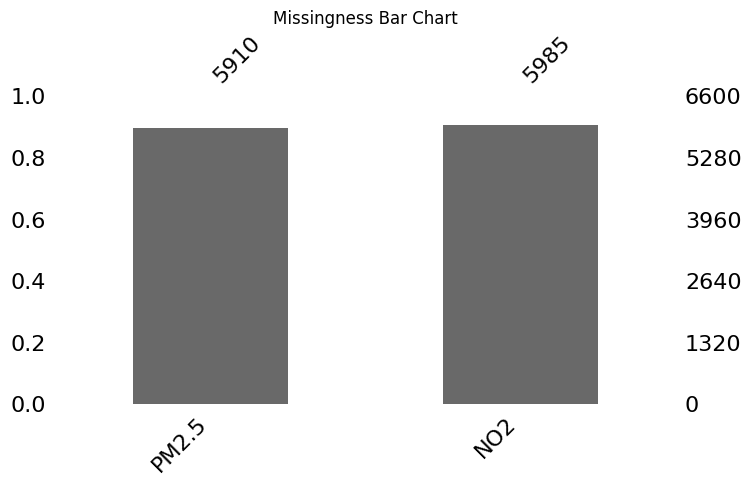

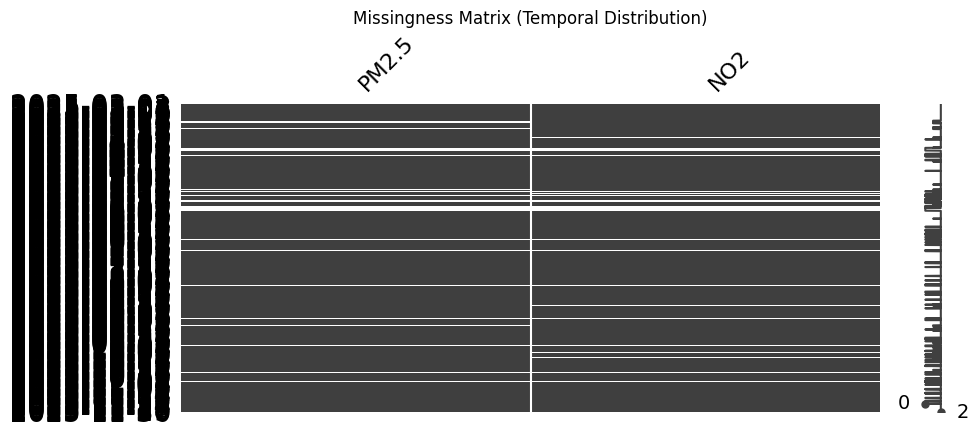

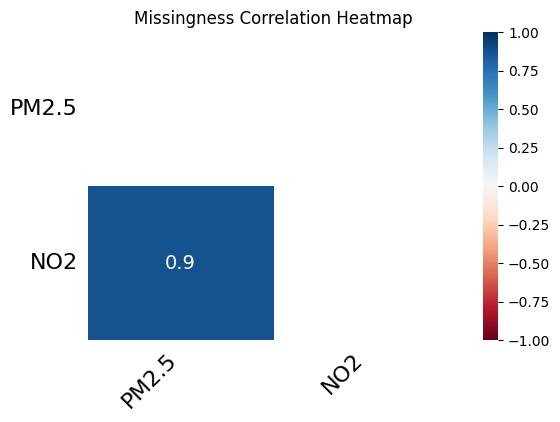

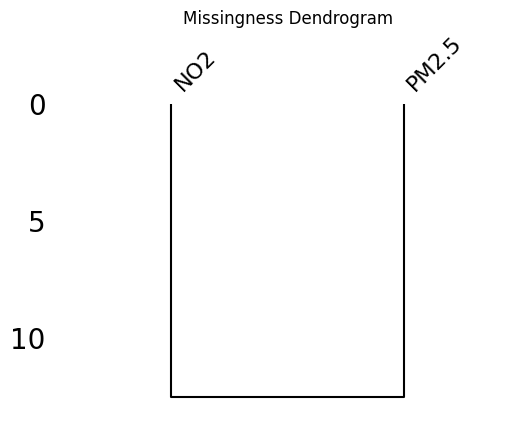

In [14]:
import missingno as msno

# Create combined hourly table for missingness analysis
df_combined = pd.DataFrame({"PM2.5": pm, "NO2": no2})

# 1. Bar Plot
msno.bar(df_combined, figsize=(8, 4))
plt.title("Missingness Bar Chart")
plt.show()

# 2. Matrix Plot
msno.matrix(df_combined, figsize=(10, 4), freq="D")
plt.title("Missingness Matrix (Temporal Distribution)")
plt.show()

# 3. Heatmap
msno.heatmap(df_combined, figsize=(6, 4))
plt.title("Missingness Correlation Heatmap")
plt.show()

# 4. Dendrogram
msno.dendrogram(df_combined, figsize=(6, 4))
plt.title("Missingness Dendrogram")
plt.show()

The bar chart shows 690 missing PM2.5 hours and 615 missing NO2 hours in the 6,600-hour calendar. The matrix shows when the missing values occur. The heatmap and dendrogram compare the two pollutants' missingness patterns. Both pollutants are missing at the same time for 574 hours, but this overlap does not prove the reason for the gaps.

### 4.1 Missingness by month

Monthly missing-hour percentages and a chi-square test compare missing versus observed hours across months. A small p-value is evidence that missingness changes by month, so missingness is not independent of calendar month (and the MCAR assumption is questionable). This association alone does not establish a specific missing-at-random mechanism.

In [15]:
monthly_missing = pd.DataFrame({"PM2.5": pm_missing, "NO2": no2_missing}).resample("MS").mean()
monthly_missing = monthly_missing.loc[monthly_missing.index.month <= 11]
display((monthly_missing * 100).round(2).rename_axis("month"))

,PM2.5,NO2
month,,
2025-03-01,11.10,0.14
2025-04-01,14.72,15.00
2025-05-01,16.13,15.99
2025-06-01,17.22,19.17
2025-07-01,5.38,5.24
2025-08-01,7.53,8.06
2025-09-01,6.39,4.44
2025-10-01,9.01,9.27
2025-11-01,6.81,6.81


In [16]:
for name, series in [("PM2.5", pm), ("NO2", no2)]:
    study_hours = series.index <= pd.Timestamp("2025-11-30 23:00:00")
    month_number = series.index[study_hours].month
    table = pd.crosstab(month_number, series.loc[study_hours].isna())
    statistic, p_value, degrees_freedom, _ = chi2_contingency(table)
    print(
        f"{name}: chi-square={statistic:.2f}, df={degrees_freedom}, "
        f"p-value={p_value:.4g}"
    )
    assert p_value < 0.05

PM2.5: chi-square=126.99, df=8, p-value=1.187e-23
NO2: chi-square=264.60, df=8, p-value=1.376e-52


### 4.2 Compare missingness over time

The upper panel shows monthly missing percentages; the lower panel compares the daily number of missing hours in the two sensors. Overlapping periods support a station-wide downtime hypothesis, while unmatched missing hours may reflect sensor-specific data loss.

<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


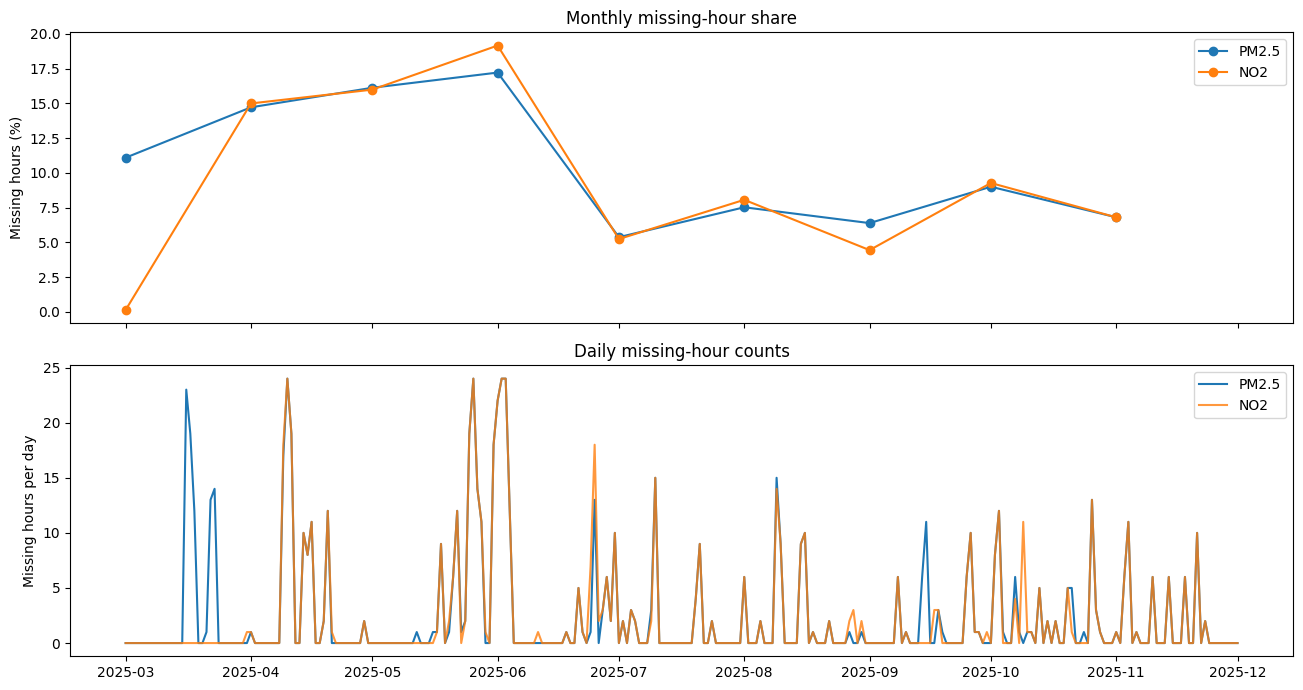

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(monthly_missing.index, monthly_missing["PM2.5"] * 100, marker="o", label="PM2.5")
axes[0].plot(monthly_missing.index, monthly_missing["NO2"] * 100, marker="o", label="NO2")
axes[0].set_ylabel("Missing hours (%)")
axes[0].set_title("Monthly missing-hour share")
axes[0].legend()

axes[1].plot(pm_missing.resample("D").sum(), label="PM2.5")
axes[1].plot(no2_missing.resample("D").sum(), label="NO2", alpha=0.8)
axes[1].set_ylabel("Missing hours per day")
axes[1].set_title("Daily missing-hour counts")
axes[1].legend()
fig.tight_layout()
plt.show()

## 5. Compare missing-value treatments

For sensitivity analysis, time interpolation is restricted to internal runs of at most six hours. Longer gaps are not bridged by interpolation. K-nearest-neighbours (KNN) and iterative MICE-style imputation use NO2 and cyclical time features. To compare methods fairly, the same deterministic 10% sample of measured PM2.5 hours is masked for each method and scored against its known measurements with MAE and RMSE. These scores are a diagnostic comparison and do not imply that estimates are observations.

In [18]:
def interpolate_short_gaps(series, max_gap=6):
    """Time-interpolate only internal missing runs no longer than max_gap."""
    gaps = missing_gap_table(series)
    result = series.copy()
    interpolated = series.interpolate(method="time", limit_area="inside")
    for gap in gaps.loc[gaps["hours"].le(max_gap)].itertuples(index=False):
        result.loc[gap.start:gap.end] = interpolated.loc[gap.start:gap.end]
    return result

In [19]:
def imputation_features(pm_values, no2_values):
    """Combine pollutant values with cyclical local-time features."""
    index = pm_values.index
    hour_angle = 2 * np.pi * index.hour / 24
    year_angle = 2 * np.pi * index.dayofyear / 365.25
    return pd.DataFrame(
        {
            "pm25": pm_values.to_numpy(dtype=float),
            "no2": no2_values.reindex(index).to_numpy(dtype=float),
            "hour_sin": np.sin(hour_angle),
            "hour_cos": np.cos(hour_angle),
            "year_sin": np.sin(year_angle),
            "year_cos": np.cos(year_angle),
        },
        index=index,
    )

In [20]:
def multivariate_pm_imputation(pm_values, no2_values, method):
    """Estimate PM2.5 using scaled KNN or iterative imputation features."""
    features = imputation_features(pm_values, no2_values)
    scaler = StandardScaler()
    scaled = scaler.fit_transform(features)

    if method == "KNN":
        imputer = KNNImputer(n_neighbors=5, weights="distance")
    elif method == "MICE":
        imputer = IterativeImputer(max_iter=10, random_state=RANDOM_STATE)
    else:
        raise ValueError("method must be 'KNN' or 'MICE'")

    completed = scaler.inverse_transform(imputer.fit_transform(scaled))
    return pd.Series(completed[:, 0], index=features.index, name="pm25")

In [21]:
observed_pm = pm.dropna()
rng = np.random.default_rng(RANDOM_STATE)
validation_index = rng.choice(
    observed_pm.index.to_numpy(),
    size=max(1, int(0.10 * len(observed_pm))),
    replace=False,
)
validation_truth = pm.loc[validation_index]
masked_pm = pm.copy()
masked_pm.loc[validation_index] = np.nan
print("Held-out measured hours:", len(validation_index))

Held-out measured hours: 591


In [22]:
validation_predictions = {
    "Time interpolation (<=6h)": interpolate_short_gaps(masked_pm).loc[validation_index],
    "KNN": multivariate_pm_imputation(masked_pm, no2, "KNN").loc[validation_index],
    "MICE": multivariate_pm_imputation(masked_pm, no2, "MICE").loc[validation_index],
}

validation_scores = pd.DataFrame(
    {
        method: {
            "MAE": np.mean(np.abs(prediction - validation_truth)),
            "RMSE": np.sqrt(np.mean((prediction - validation_truth) ** 2)),
        }
        for method, prediction in validation_predictions.items()
    }
).T
print("Masked-observation validation scores (lower is better):")
display(validation_scores.round(3))

Masked-observation validation scores (lower is better):


,MAE,RMSE
Time interpolation (<=6h),4.845,10.511
KNN,19.300,35.630
MICE,31.831,46.375


### 5.1 Inspect estimated distributions

The observed hourly distribution is compared with estimates only at missing PM2.5 timestamps. A smooth-looking distribution is not sufficient evidence that imputation is accurate, so interpret these plots alongside the held-out error scores. The raw series stays unchanged.

In [23]:
pm_short = interpolate_short_gaps(pm)
pm_knn = multivariate_pm_imputation(pm, no2, "KNN")
pm_mice = multivariate_pm_imputation(pm, no2, "MICE")

imputation_summary = pd.DataFrame(
    {
        "observed_only": pm.dropna(),
        "short_gap_treatment": pm_short,
        "all_missing_filled_KNN": pm_knn,
        "all_missing_filled_MICE": pm_mice,
    }
).agg(["count", "mean", "std", "skew"]).T
print("Summary statistics for observed and estimated series:")
display(imputation_summary.round(3))

Summary statistics for observed and estimated series:


,count,mean,std,skew
observed_only,5910.0,59.431,62.188,3.641
short_gap_treatment,6040.0,60.250,66.458,4.409
all_missing_filled_KNN,6600.0,59.070,60.236,3.688
all_missing_filled_MICE,6600.0,58.888,59.718,3.708


<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


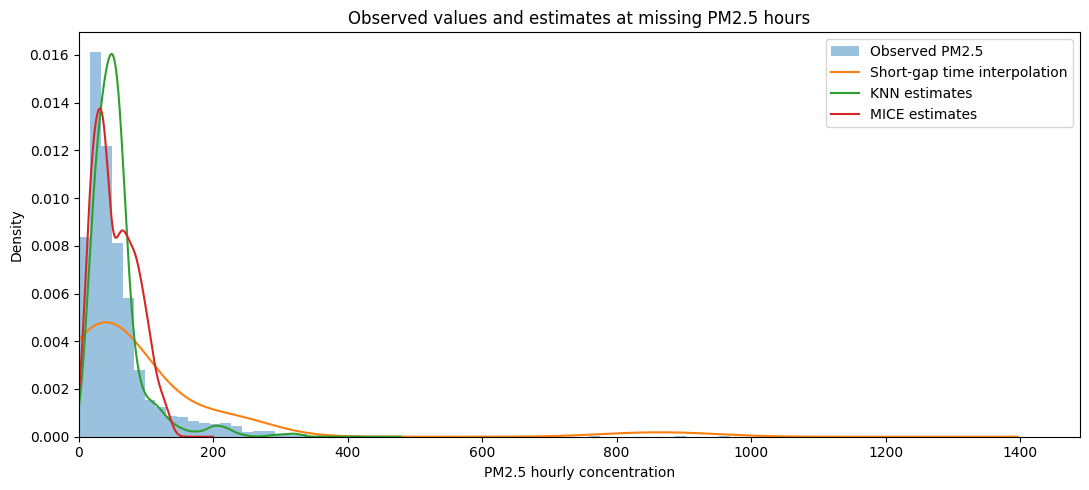

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(pm.dropna(), bins=60, density=True, alpha=0.45, label="Observed PM2.5")
for label, estimates in [
    ("Short-gap time interpolation", pm_short),
    ("KNN estimates", pm_knn),
    ("MICE estimates", pm_mice),
]:
    values = estimates.loc[pm.isna()].dropna()
    if len(values) > 1:
        values.plot(kind="kde", ax=ax, label=label)
ax.set_xlim(left=0)
ax.set_xlabel("PM2.5 hourly concentration")
ax.set_ylabel("Density")
ax.set_title("Observed values and estimates at missing PM2.5 hours")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Create and check the daily pollution dataset

The final daily means include observed hourly values and internal short-gap interpolation only. `pm25_hours` records the number of real, non-imputed PM2.5 measurements available on that date. Longer gaps are not filled. Exact-zero NO2 values are flagged as likely sensor-floor readings and masked only in the daily-analysis copy; the raw NO2 series remains available for audit.

Four dates have no hourly measurements for either pollutant. Their daily means and ratio are left null rather than inventing an entire missing day's values. The calendar retains all 275 dates from March 1 through November 30.

In [25]:
no2_zero_times = no2.index[no2.eq(0)]
no2_for_daily = no2.mask(no2.eq(0))

study_start = pd.Timestamp("2025-03-01")
study_end = pd.Timestamp("2025-11-30")
pm_daily_hourly = interpolate_short_gaps(pm)
no2_daily_hourly = interpolate_short_gaps(no2_for_daily)

pm_daily = pm_daily_hourly.loc["2025-03-01":"2025-11-30"].resample("D").mean()
no2_daily = no2_daily_hourly.loc["2025-03-01":"2025-11-30"].resample("D").mean()
pm25_hours = pm.loc["2025-03-01":"2025-11-30"].resample("D").count().astype("int64")

In [26]:
daily = pd.DataFrame(
    {
        "date": pm_daily.index,
        "pm25": pm_daily.to_numpy(),
        "no2": no2_daily.reindex(pm_daily.index).to_numpy(),
        "pm25_hours": pm25_hours.to_numpy(),
    }
)
daily["pm_no2_ratio"] = daily["pm25"] / daily["no2"]
daily = daily[["date", "pm25", "no2", "pm25_hours", "pm_no2_ratio"]]

print("Daily dataset shape:", daily.shape)
display(daily.head())
display(daily.tail())

Daily dataset shape: (275, 5)


,date,pm25,no2,pm25_hours,pm_no2_ratio
0,2025-03-01,51.842105,32.136842,19,1.613167
1,2025-03-02,38.208333,26.324167,24,1.451455
2,2025-03-03,56.916667,45.537500,24,1.249886
3,2025-03-04,45.916667,25.720833,24,1.785194
4,2025-03-05,27.333333,23.583333,24,1.159011


,date,pm25,no2,pm25_hours,pm_no2_ratio
270,2025-11-26,138.595833,27.304167,24,5.075996
271,2025-11-27,176.250000,39.834583,24,4.424547
272,2025-11-28,161.900000,38.254167,24,4.232219
273,2025-11-29,119.383333,39.737500,24,3.004299
274,2025-11-30,123.495833,33.608333,24,3.674560


### 6.1 Check daily coverage and missing values

Before saving, inspect the daily table, missing values by column, and the number of real PM2.5 observations per day. The four expected full-outage dates are the only dates allowed to have missing primary aggregation values (`pm25`, `no2`, and `pm_no2_ratio`).

In [27]:
expected_outage_dates = pd.to_datetime(
    ["2025-04-10", "2025-05-26", "2025-06-02", "2025-06-03"]
)

print("Missing values by column:")
print(daily.isna().sum())
print("Real PM2.5 hours per day:")
display(daily["pm25_hours"].describe().to_frame())
print("Days with no PM2.5 measurement:")
display(daily.loc[daily["pm25"].isna(), ["date", "pm25", "no2", "pm25_hours"]])

Missing values by column:
date            0
pm25            4
no2             4
pm25_hours      0
pm_no2_ratio    4
dtype: int64
Real PM2.5 hours per day:
Days with no PM2.5 measurement:


,pm25_hours
count,275.000000
mean,21.472727
std,5.202661
min,0.000000
25%,22.000000
50%,24.000000
75%,24.000000
max,24.000000


,date,pm25,no2,pm25_hours
40,2025-04-10,NaN,NaN,0
86,2025-05-26,NaN,NaN,0
93,2025-06-02,NaN,NaN,0
94,2025-06-03,NaN,NaN,0


In [28]:
expected_columns = ["date", "pm25", "no2", "pm25_hours", "pm_no2_ratio"]
assert len(daily) == 275
assert daily["date"].min() == study_start and daily["date"].max() == study_end
assert daily.columns.tolist() == expected_columns
assert daily["pm25_hours"].between(0, 24).all()

for column in ["pm25", "no2", "pm_no2_ratio"]:
    null_dates = pd.to_datetime(daily.loc[daily[column].isna(), "date"]).tolist()
    assert null_dates == list(expected_outage_dates), f"Unexpected missing dates in {column}: {null_dates}"

assert daily.loc[daily["pm25"].notna(), "pm25"].ge(0).all()
assert daily.loc[daily["no2"].notna(), "no2"].gt(0).all()
assert daily.loc[daily["pm_no2_ratio"].notna(), "pm_no2_ratio"].ge(0).all()
print("Daily data checks passed.")

Daily data checks passed.


In [29]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
daily.to_csv(DAILY_PATH, index=False, date_format="%Y-%m-%d")
print("Saved daily data to:", DAILY_PATH)

Saved daily data to: C:\Users\YASHVI PATEL\Documents\Study Only\EDA\EDA-PROJECT\EDA-Group-Project\data\processed\pollution_daily.csv


### 6.2 Verify the saved file

Read the exported CSV back from disk and check its shape, columns, date bounds, and missing-value counts. This catches problems in the deliverable itself, rather than only testing the in-memory DataFrame.

In [30]:
daily_check = pd.read_csv(DAILY_PATH, parse_dates=["date"])
print("Saved file shape:", daily_check.shape)
print("Saved file columns:", daily_check.columns.tolist())
print("Saved file date range:", daily_check["date"].min(), "to", daily_check["date"].max())
print("Saved file null counts:")
print(daily_check.isna().sum())
display(daily_check.head())

Saved file shape: (275, 5)
Saved file columns: ['date', 'pm25', 'no2', 'pm25_hours', 'pm_no2_ratio']
Saved file date range: 2025-03-01 00:00:00 to 2025-11-30 00:00:00
Saved file null counts:
date            0
pm25            4
no2             4
pm25_hours      0
pm_no2_ratio    4
dtype: int64


,date,pm25,no2,pm25_hours,pm_no2_ratio
0,2025-03-01,51.842105,32.136842,19,1.613167
1,2025-03-02,38.208333,26.324167,24,1.451455
2,2025-03-03,56.916667,45.537500,24,1.249886
3,2025-03-04,45.916667,25.720833,24,1.785194
4,2025-03-05,27.333333,23.583333,24,1.159011


In [31]:
assert daily_check.shape == (275, 5)
assert daily_check.columns.tolist() == ["date", "pm25", "no2", "pm25_hours", "pm_no2_ratio"]
assert daily_check["date"].min() == study_start
assert daily_check["date"].max() == study_end
assert daily_check[["pm25", "no2", "pm_no2_ratio"]].isna().sum().to_dict() == {
    "pm25": 4,
    "no2": 4,
    "pm_no2_ratio": 4,
}
assert daily_check["pm25_hours"].between(0, 24).all()
print("Saved CSV checks passed.")

Saved CSV checks passed.


## 7. Outlier identification and treatment choices

IQR fences and an absolute z-score greater than 3 flag unusually high observations by different definitions. Because PM2.5 is strongly right-skewed, the mean and standard deviation are affected by the high-concentration tail, and the two methods flag different numbers of readings. These flags are screening tools, not automatic evidence of faulty sensors.

The October 21 maximum follows Diwali on October 20. Measurements before the peak are missing for several hours, but the available readings from 06:00 through 09:00 show a consecutive elevated peak and decay. The event context and observed pattern support retaining the measured peak, not clipping it. IQR capping, 5th/95th percentile winsorization, and a log transform are shown only as sensitivity comparisons; none replaces raw values in the daily export.

In [32]:
pm_observed = pm.dropna()
q1, q3 = pm_observed.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

z_scores = (pm_observed - pm_observed.mean()) / pm_observed.std(ddof=1)
iqr_outliers = pm_observed[(pm_observed < lower_fence) | (pm_observed > upper_fence)]
z_outliers = pm_observed[z_scores.abs() > 3]

print("IQR lower fence:", round(lower_fence, 3))
print("IQR upper fence:", round(upper_fence, 3), "?g/m?")
print("IQR outlier hours:", len(iqr_outliers))
print("Z-score outlier hours (|z| > 3):", len(z_outliers))
print("PM2.5 skewness:", round(pm_observed.skew(), 3))

IQR lower fence: -44.675
IQR upper fence: 137.125 ?g/m?
IQR outlier hours: 510
Z-score outlier hours (|z| > 3): 126
PM2.5 skewness: 3.641


In [33]:
peak_time = pm_observed.idxmax()
pre_peak = pm.loc["2025-10-21 00:00:00"]
peak_period = pm.loc["2025-10-21 06:00:00":"2025-10-21 09:00:00"]

print("Highest PM2.5 reading:", pm_observed.max(), "?g/m? at", peak_time)
print("Last available pre-peak value at midnight:", pre_peak)
print("Hours from 01:00 to 05:00 are missing; available post-peak values:")
display(peak_period.to_frame("PM2.5 (?g/m?)"))

Highest PM2.5 reading: 968.0 ?g/m? at 2025-10-21 06:00:00
Last available pre-peak value at midnight: 760.0
Hours from 01:00 to 05:00 are missing; available post-peak values:


,PM2.5 (?g/m?)
time,
2025-10-21 06:00:00,968.0
2025-10-21 07:00:00,899.0
2025-10-21 08:00:00,608.0
2025-10-21 09:00:00,311.0


In [34]:
no2_zero_rows = no2_raw.loc[
    no2_raw["value"].eq(0), ["time", "value", "unit", "sensor_id"]
]
print("Exact-zero NO2 readings flagged as possible sensor-floor anomalies:")
display(no2_zero_rows)
print("These readings remain in the raw series; only the daily-analysis copy masks them.")

Exact-zero NO2 readings flagged as possible sensor-floor anomalies:
These readings remain in the raw series; only the daily-analysis copy masks them.


,time,value,unit,sensor_id
2449,2025-06-24 15:00:00,0.0,ppb,12235309
3582,2025-08-16 10:00:00,0.0,ppb,12235309
4892,2025-10-13 10:00:00,0.0,ppb,12235309


In [35]:
cap_iqr = pm_observed.clip(lower=lower_fence, upper=upper_fence)
p05, p95 = pm_observed.quantile([0.05, 0.95])
winsor_5pct = pm_observed.clip(lower=p05, upper=p95)
log_pm = np.log1p(pm_observed)

outlier_comparison = pd.DataFrame(
    {
        "raw": [pm_observed.min(), pm_observed.max(), pm_observed.mean(), pm_observed.std(), pm_observed.skew()],
        "IQR capped": [cap_iqr.min(), cap_iqr.max(), cap_iqr.mean(), cap_iqr.std(), cap_iqr.skew()],
        "5/95% winsorized": [winsor_5pct.min(), winsor_5pct.max(), winsor_5pct.mean(), winsor_5pct.std(), winsor_5pct.skew()],
        "log1p(raw)": [log_pm.min(), log_pm.max(), log_pm.mean(), log_pm.std(), log_pm.skew()],
    },
    index=["minimum", "maximum", "mean", "standard deviation", "skewness"],
).T
print("Diagnostic comparison only; the daily file remains uncapped and untransformed:")
display(outlier_comparison.round(3))

Diagnostic comparison only; the daily file remains uncapped and untransformed:


,minimum,maximum,mean,standard deviation,skewness
raw,1.000,968.000,59.431,62.188,3.641
IQR capped,1.000,137.125,52.150,37.442,1.060
5/95% winsorized,10.890,188.550,55.792,46.095,1.610
log1p(raw),0.693,6.876,3.755,0.816,0.120


<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


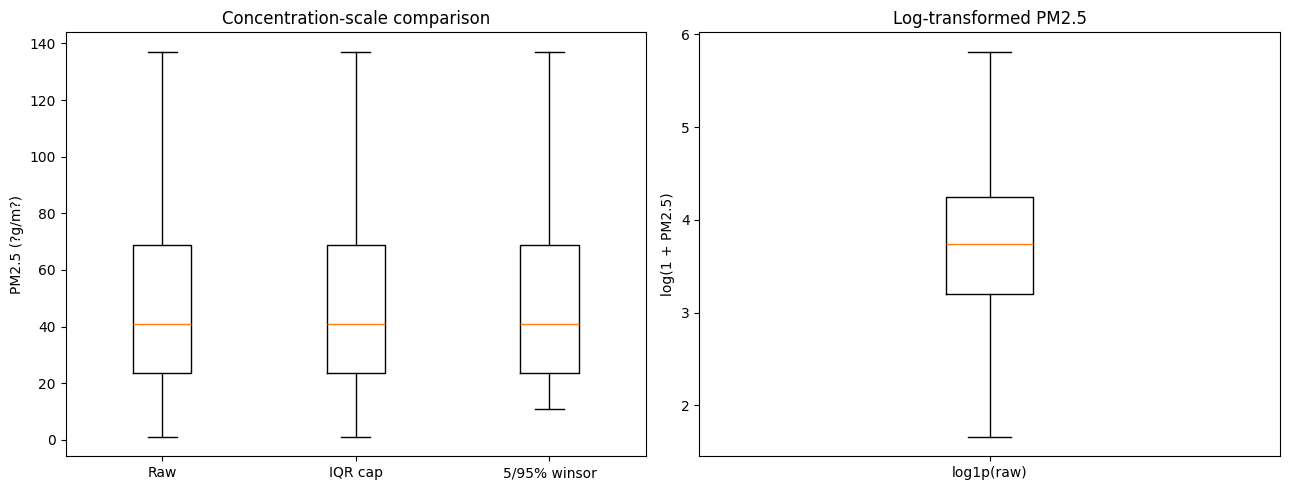

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].boxplot(
    [pm_observed, cap_iqr, winsor_5pct],
    tick_labels=["Raw", "IQR cap", "5/95% winsor"],
    showfliers=False,
)
axes[0].set_ylabel("PM2.5 (?g/m?)")
axes[0].set_title("Concentration-scale comparison")

axes[1].boxplot([log_pm], tick_labels=["log1p(raw)"], showfliers=False)
axes[1].set_ylabel("log(1 + PM2.5)")
axes[1].set_title("Log-transformed PM2.5")
fig.tight_layout()
plt.show()

### 7.1 Final checks

The final assertions verify the expected IQR and z-score counts, the retained Diwali-period maximum and its observed subsequent readings, all three NO2 zero-value timestamps, and constraints on the exported daily dataset. The outlier flags do not delete, cap, or overwrite hourly source measurements.

In [37]:
expected_no2_zero_times = pd.to_datetime(
    ["2025-06-24 15:00:00", "2025-08-16 10:00:00", "2025-10-13 10:00:00"]
)

assert np.isclose(upper_fence, 137.125)
assert len(iqr_outliers) == 510
assert len(z_outliers) == 126
assert pm_observed.max() == 968
assert peak_time == pd.Timestamp("2025-10-21 06:00:00")
assert pre_peak == 760
assert peak_period.tolist() == [968, 899, 608, 311]
assert no2_zero_rows["time"].tolist() == list(expected_no2_zero_times)
assert daily_check.shape == (275, 5)
assert daily_check["pm25"].isna().sum() == 4
assert daily_check["no2"].isna().sum() == 4
assert daily_check["pm_no2_ratio"].isna().sum() == 4
print("Final data and outlier checks passed.")

Final data and outlier checks passed.
